# Fake News Classification

In today's blog post, I'll be using `keras` to create machine learning models to differentiate fake news articles from real ones. The data source is accessible from [Kaggle](https://www.kaggle.com/clmentbisaillon/fake-and-real-news-dataset) but I loaded it from the [PIC16B github page](https://raw.githubusercontent.com/pic16b-ucla/25W/refs/heads/main/datasets/fake_news_train.csv).  

<br>

The data contains a column for `title` and `text` of each article, as well as `fake`. My first model will use only the `title`, the second will use only the `text`, and the third will use both.
<br><br>

## Imports:

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
from keras import utils, datasets, models, layers, ops
from keras.layers import TextVectorization

import tensorflow_datasets as tfds
import keras
from matplotlib import pyplot as plt
import pathlib
import pandas as pd
import numpy as np
import re
import string
import tensorflow as tf
from sklearn.feature_extraction import text
from sklearn.decomposition import PCA
import plotly.express as px
import plotly.io as pio
# pio.renderers.default="iframe"
from matplotlib import pyplot as plt

stop = text.ENGLISH_STOP_WORDS

## Load the Data:

In [2]:
train_url = "https://raw.githubusercontent.com/pic16b-ucla/25W/refs/heads/main/datasets/fake_news_train.csv"

In [3]:
df  = pd.read_csv(train_url)
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22449 entries, 0 to 22448
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  22449 non-null  int64 
 1   title       22449 non-null  object
 2   text        22449 non-null  object
 3   fake        22449 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 701.7+ KB
None


,Unnamed: 0,title,text,fake
0,17366,Merkel: Strong result for Austria's FPO 'big c...,German Chancellor Angela Merkel said on Monday...,0
1,5634,Trump says Pence will lead voter fraud panel,"WEST PALM BEACH, Fla.President Donald Trump sa...",0
2,17487,JUST IN: SUSPECTED LEAKER and “Close Confidant...,"On December 5, 2017, Circa s Sara Carter warne...",1
3,12217,Thyssenkrupp has offered help to Argentina ove...,"Germany s Thyssenkrupp, has offered assistance...",0
4,5535,Trump say appeals court decision on travel ban...,President Donald Trump on Thursday called the ...,0


# Making the Dataset

Now that we've loaded the data from the source into a dataframe, we can put it into a `tf.data.Dataset` object with this function:

In [4]:
def make_dataset(df):
  pat = r'\b(?:{})\b'.format('|'.join(stop))

  #prepare the data by making it lowercase and removing stopwords
  for col in ['title', 'text']:
    df[col] = df[col].str.lower()
    df[col] = df[col].str.replace(pat, '')
    df[col] = df[col].str.replace(r'\s+', ' ')

  #make the dataset using nested dictionary in a tuple
  data = tf.data.Dataset.from_tensor_slices(
    (
        {
            "title" : df[["title"]],
            "text" : df[["text"]]
        },
        (
            df[["fake"]],
        )
    )
)
  return data.batch(100)

In [5]:
data = make_dataset(df)
data.element_spec

({'title': TensorSpec(shape=(None, 1), dtype=tf.string, name=None),
  'text': TensorSpec(shape=(None, 1), dtype=tf.string, name=None)},
 (TensorSpec(shape=(None, 1), dtype=tf.int64, name=None),))

`data.element_spec` tells us what kind of elements we have in our dataset. In this one, we have the `title`, `text`, and the output, which corresponds to whether the article is fake or not (the `fake` column in the df).
<br><br>
## Preparing the Data:

After making and shuffling the data, we split 20% for validation (the rest for training). Keep in mind that we batched by 100 in the `make_dataset()` function, so this really means that we have 180*100 = 18,000 elements in the training set.

In [6]:
data = data.shuffle(buffer_size = len(data), reshuffle_each_iteration=False)

# train_size = int(0.8*len(data))
val_size   = int(0.2*len(data))

val   = data.take(val_size)
train = data.skip(val_size)

print(len(train), len(val))

180 45


# Building the Models

Now we are ready to build the models. Since we have two different inputs, we will use the `keras.Functional` API since it is more flexible than `keras.Sequential`.
<br><br>
## Text Vectorization:

We want to embed the text as vectors in order to understand how the model quantifies words, which gives some insight into how they are related to each other -- for this we need a text vectorization layer. In the actual model, we'll follow this with an embedding layer and then after running the models we can plot the embeddings to see what they look like.

<br>

Since we're making a vectorization layer for three different models, I wrote this function to do it. It's important to standardize the text before running it through the vectorization.

In [7]:
#preparing a text vectorization layer for the models

def standardization(input_data):
    lowercase = tf.strings.lower(input_data)
    no_punctuation = tf.strings.regex_replace(lowercase,
                                  '[%s]' % re.escape(string.punctuation),'')
    return no_punctuation

def make_vector_layer(f, size_vocabulary):

  """
  args:
        f: a map to adapt the layer according to train data
            (maps x, y to the data you want to use according to the dict defined in the input)
        size_vocabulary: number of words to consider
  returns: a text vectorization layer adapted to the train data as specified by f
  """

  vector_layer = TextVectorization(
    standardize=standardization,
    max_tokens=size_vocabulary,
    output_mode='int',
    output_sequence_length=500)

  vector_layer.adapt(train.map(f))

  return vector_layer

The `f` argument for `make_vector_layer()` is a map that is applied to the `train` dataset to tell the layer what to adapt to. For each model, this corresponds to the input we want to consider. Recall that we structured the dataset as the tuple (x,y) where x is the dictionary {'title' : df[['title']], 'text' : df[['text']]} and y is df[['fake']]. For example, f1 maps (x,y) to x['title'], which accesses the element's title.

In [8]:
#Get the vector layer for Model 1

f1 = lambda x, y: x["title"]
model1_vector_layer = make_vector_layer(f1, 2000)

## Inputs:

When we build the model we must define ahead of time what kind of inputs it will take.

In [9]:
#Define the inputs
title_input = keras.Input(
    shape = (1,),
    name = "title",
    dtype = "string"
)
text_input = keras.Input(
    shape = (1,),
    name = "text",
    dtype = "string"
)

## More Layers

Now we can stack more layers to build the rest of Model 1. These are somewhat arbitrary; you can try different ones to see what works best.

In [10]:
#make pipeline for model 1
title_features = model1_vector_layer(title_input)
title_features = layers.Embedding(2000, 10, name = "embedding1")(title_features)
title_features = layers.Dropout(0.2)(title_features)
title_features = layers.GlobalAveragePooling1D()(title_features)
title_features = layers.Dropout(0.2)(title_features)
title_features = layers.Dense(64, activation='relu')(title_features)
title_features = layers.Dense(32, activation='relu')(title_features)

#define the output
model1_output = layers.Dense(2, name='fake')(title_features)

In [11]:
#put the model together
model1 = keras.Model(
    inputs = title_input,
    outputs = model1_output
)

# Running the Model

Now we get to compile, train, and visualize Model 1. Since we will also do this for Model 2 and 3, I made a function to do it:

In [12]:
def run_model(model, diagram_name):
  """

  """

  callback = keras.callbacks.EarlyStopping(start_from_epoch = 10, patience=3, restore_best_weights=True)

  model.compile(optimizer = "adam",
              loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

  #visualize the model
  keras.utils.plot_model(model, f"hw6_{diagram_name}.png", show_shapes=True,
                       show_layer_names=True,
                       show_layer_activations=True)

  #train the model
  history = model.fit(train,
                    validation_data=val,
                    epochs = 50,
                    verbose = True,
                    callbacks = [callback])

  plt.plot(history.history["accuracy"],label='training')
  plt.plot(history.history["val_accuracy"],label='validation')
  plt.legend()

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: title
Received: inputs=['Tensor(shape=(None, 1))']
  warnings.warn(msg)


180/180 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.5183 - loss: 0.6924 - val_accuracy: 0.5189 - val_loss: 0.6918
Epoch 2/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.5310 - loss: 0.6904 - val_accuracy: 0.5189 - val_loss: 0.6739
Epoch 3/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6151 - loss: 0.6537 - val_accuracy: 0.5738 - val_loss: 0.6333
Epoch 4/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7451 - loss: 0.5115 - val_accuracy: 0.7873 - val_loss: 0.4305
Epoch 5/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8124 - loss: 0.4103 - val_accuracy: 0.7896 - val_loss: 0.4207
Epoch 6/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8444 - loss: 0.3503 - val_accuracy: 0.8504 - val_loss: 0.3244
Epoch 7/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8641 - loss: 0.3211 - val_accuracy: 0.8800 - val_loss: 0.2767
Epoch 8/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8569 - loss: 0.3323 - val_accuracy: 0.8729 - va

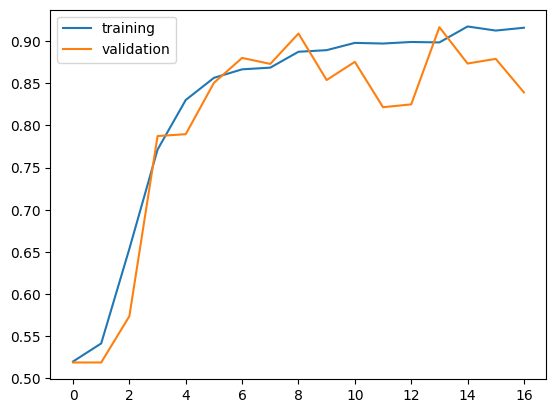

In [13]:
run_model(model1, 'model1')

The model stopped training after fewer than 50 epochs because I enabled early stopping in order to prevent overfitting. The history plot shows a sharp increase in accuracy for the first few epochs, after which it becomes nearly flat. But the model performed pretty well -- around 95%!
<br>
<br>
But what exactly does this model look like? We actually generated a diagram of the layers in the `run_model()` function using `keras.utils.plot_model`.

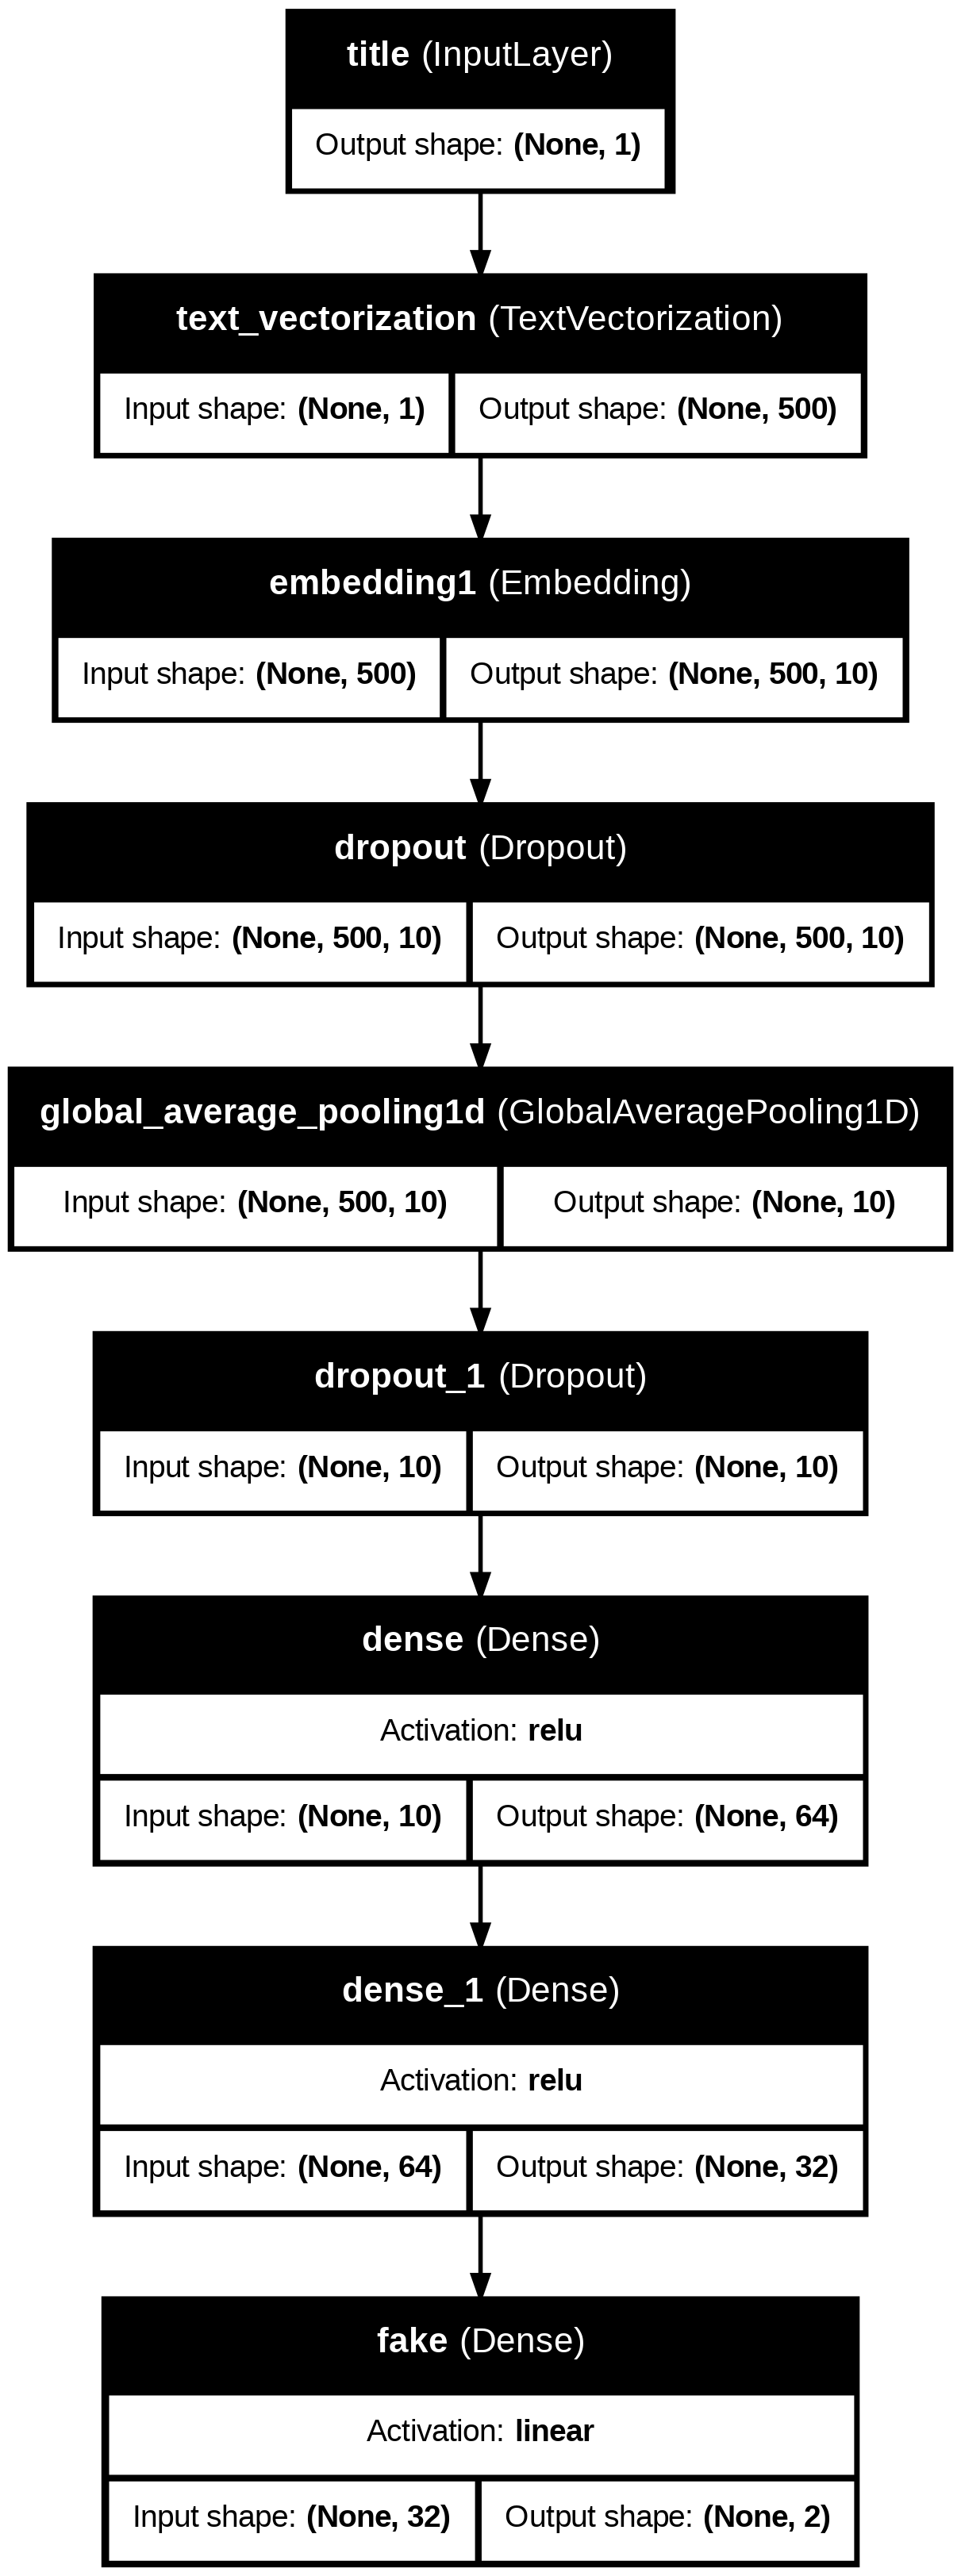

In [14]:
from IPython.display import Image
Image('hw6_model1.png', width=600, height=1300)

# Model 2

This model will be very similar to Model 1, except we now want to use the articles' `text` instead of `title`. For this reason I increased the vector layer's `max_token` (the number of words it considers) to 5000.

In [15]:
#make the vectorization layer
f2 = lambda x, y: x["text"]
model2_vector_layer = make_vector_layer(f2, 5000)

#make pipeline for model 2
text_features = model2_vector_layer(text_input)
text_features = layers.Embedding(5000, 10, name = "embedding2")(text_features)
text_features = layers.Dropout(0.2)(text_features)
text_features = layers.GlobalAveragePooling1D()(text_features)
text_features = layers.Dropout(0.2)(text_features)
text_features = layers.Dense(64, activation='relu')(text_features)
text_features = layers.Dense(32, activation='relu')(text_features)

#define the output
model2_output = layers.Dense(2, name='fake')(text_features)

#put the model together
model2 = keras.Model(
    inputs = text_input,
    outputs = model2_output
)

Epoch 1/50


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: text
Received: inputs=['Tensor(shape=(None, 1))']
  warnings.warn(msg)


180/180 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.6691 - loss: 0.5946 - val_accuracy: 0.9456 - val_loss: 0.1349
Epoch 2/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9467 - loss: 0.1426 - val_accuracy: 0.9816 - val_loss: 0.0836
Epoch 3/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9630 - loss: 0.1033 - val_accuracy: 0.9816 - val_loss: 0.0692
Epoch 4/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9700 - loss: 0.0841 - val_accuracy: 0.9758 - val_loss: 0.0743
Epoch 5/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9779 - loss: 0.0640 - val_accuracy: 0.9751 - val_loss: 0.0716
Epoch 6/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.9808 - loss: 0.0567 - val_accuracy: 0.9731 - val_loss: 0.0739
Epoch 7/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9821 - loss: 0.0508 - val_accuracy: 0.9871 - val_loss: 0.0515
Epoch 8/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9875 - loss: 0.0406 - val_accuracy: 0.976

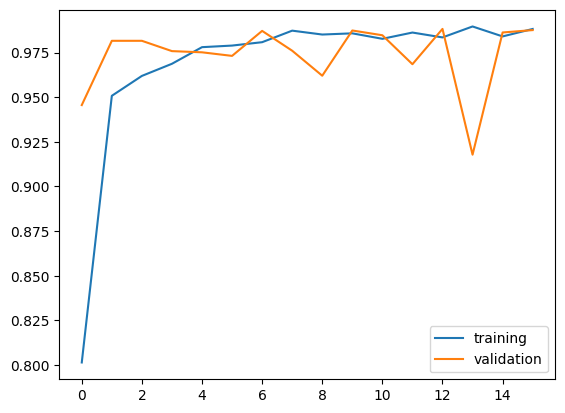

In [16]:
run_model(model2, 'model2')

Great -- Model 2 is even better than Model 1!

Here is the diagram:

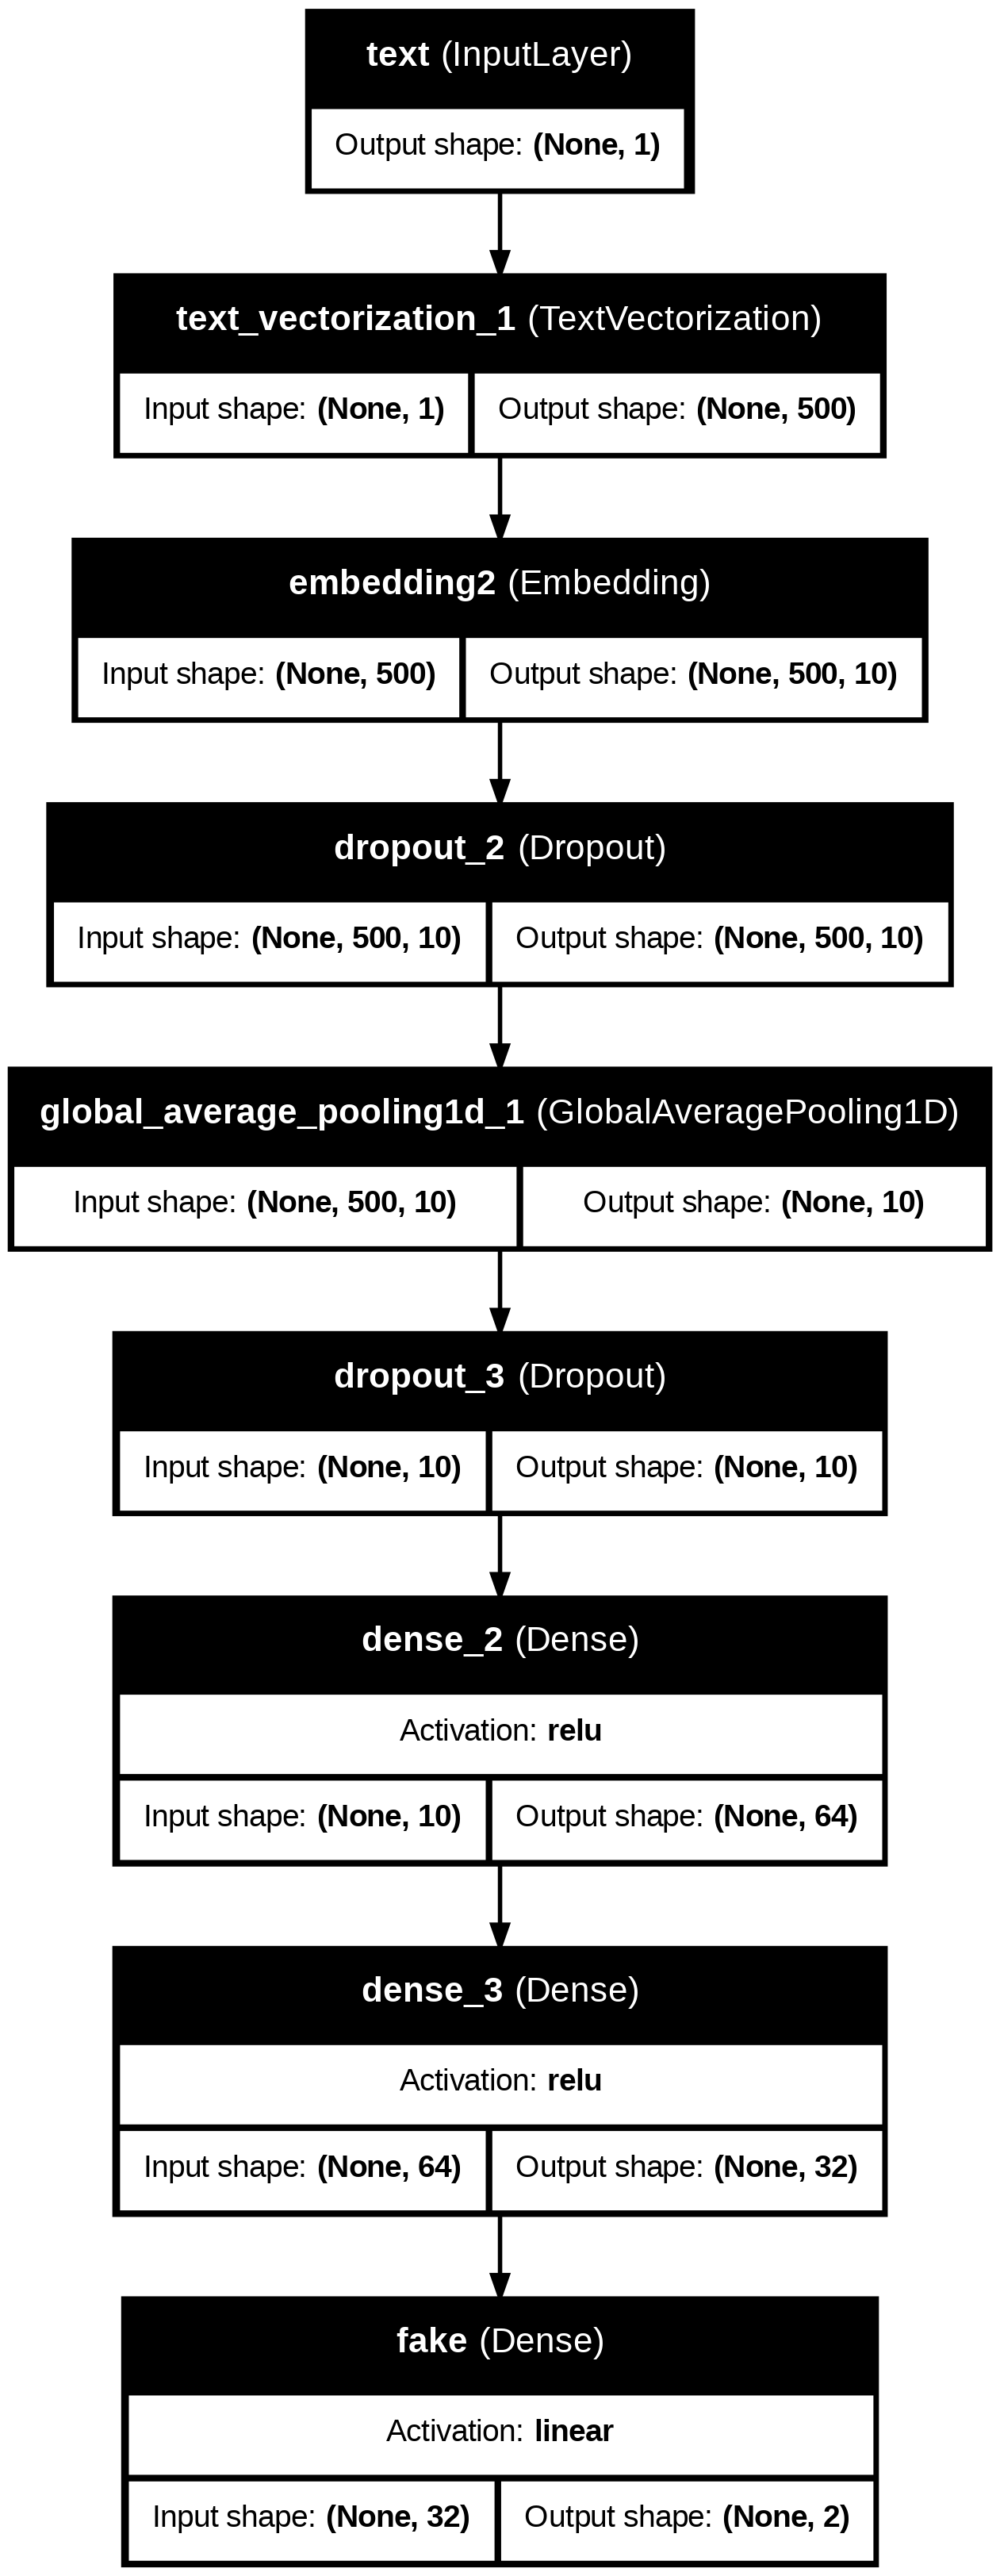

In [17]:
Image('hw6_model2.png', width=600, height=1300)

# Model 3

On to the last model! This one is a bit different than the first two because we have to consider two inputs, so we want to use shared vectorization and embedding layers so that the same words get embedded the same way. So, we'll adapt the vector layer to both inputs, then run it separately on each, then embed the vectors, then concatenate those features and build the rest of the model using the combined features.

In [18]:
#make the vectorization layer
f3 = lambda x, y: tf.concat([x["title"], x["text"]], axis=0)
model3_vector_layer = make_vector_layer(f3, 10000)

#make pipeline for model 3
title_features = model3_vector_layer(title_input)
text_features = model3_vector_layer(text_input)

features = layers.concatenate([title_features, text_features], axis=1)
features = layers.Embedding(10000, 10, name="embedding3")(features)
features = layers.Dropout(0.2)(features)
features = layers.GlobalAveragePooling1D()(features)
features = layers.Dropout(0.2)(features)
features = layers.Dense(32, activation='relu')(features)

#define output
model3_output = layers.Dense(2, name = "fake")(features)

In [19]:
#put model3 together
model3 = keras.Model(
    inputs = [title_input, text_input],
    outputs = model3_output
)

Epoch 1/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.5753 - loss: 0.6781 - val_accuracy: 0.8753 - val_loss: 0.4507
Epoch 2/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8983 - loss: 0.3593 - val_accuracy: 0.9298 - val_loss: 0.1723
Epoch 3/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9486 - loss: 0.1652 - val_accuracy: 0.9749 - val_loss: 0.1049
Epoch 4/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.9641 - loss: 0.1151 - val_accuracy: 0.9789 - val_loss: 0.0835
Epoch 5/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9730 - loss: 0.0919 - val_accuracy: 0.9829 - val_loss: 0.0687
Epoch 6/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9751 - loss: 0.0771 - val_accuracy: 0.9853 - val_loss: 0.0611
Epoch 7/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9810 - loss: 0.0649 - val_accuracy: 0.9864 - val_loss: 0.0549
Epoch 8/50
180/180 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.9838 - loss: 0.0563 - val_accu

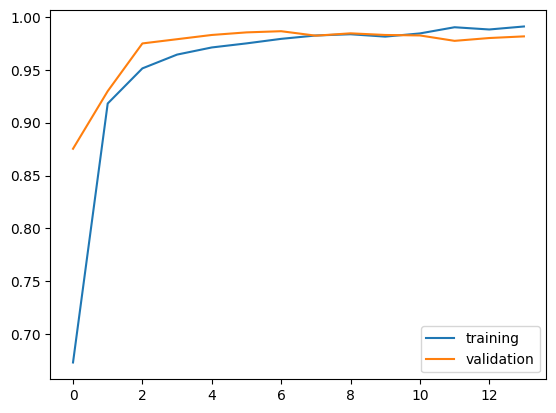

In [20]:
run_model(model3, 'model3')

Model 3 is even better than Model 2, giving approximately 98% accuracy! Here is the diagram:  


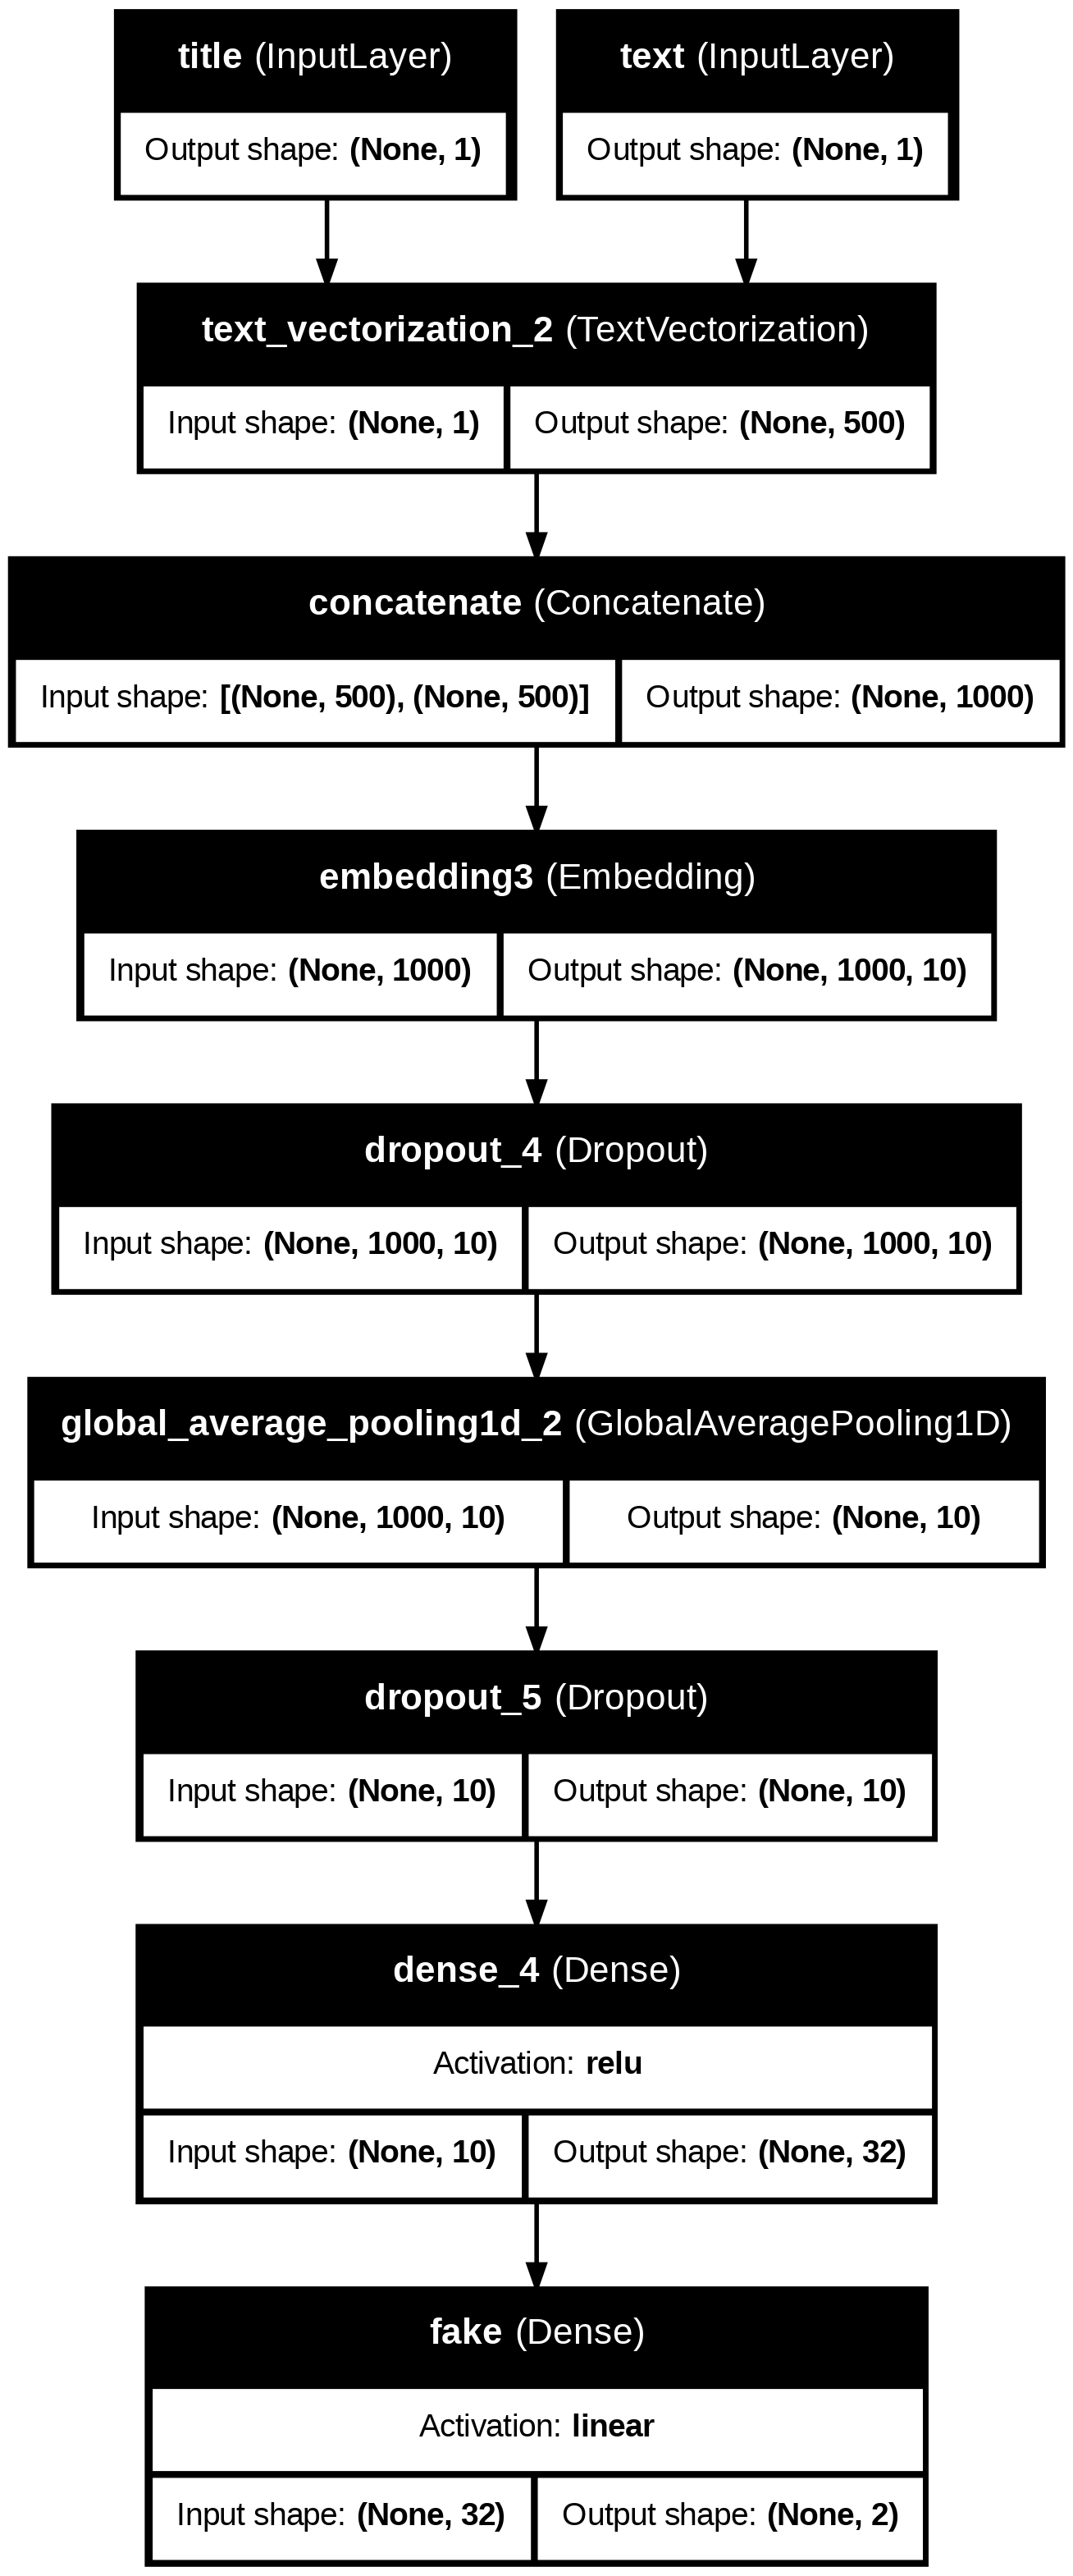

In [21]:
Image('hw6_model3.png', width=600, height=1300)

# Visualizing the Embeddings

Let's take a look at those embeddings we made along the way! I wrote a function to plot each embedding. First, the function gets the weights (the "coordinates") of each word (the "vectors"). Since these are actually 10-dimensional, it uses `pca` to collapse these into two dimensions, which we can easily plot using `Plotly`.

In [22]:
def plot_embedding(model, embedding, vec_layer):
  weights = model.get_layer(embedding).get_weights()[0] # get the weights from the embedding layer
  vocab = vec_layer.get_vocabulary()                # get the vocabulary from our data prep
  pca = PCA(n_components=2)
  weights = pca.fit_transform(weights)
  embedding_df = pd.DataFrame({
    'word' : vocab,
    'x0'   : weights[:,0],
    'x1'   : weights[:,1]
    })

  fig = px.scatter(embedding_df,
                 x = "x0",
                 y = "x1",
                 size = list(np.ones(len(embedding_df))),
                 size_max = 5,
                 hover_name = "word")
  return fig

In [ ]:
plot_embedding(model1, 'embedding1', model1_vector_layer)

![Embedding 1](newplot%20(2).png)

In [24]:
plot_embedding(model2, 'embedding2', model2_vector_layer)

![Embedding 2](newplot%20(1).png)

In [25]:
plot_embedding(model3, 'embedding3', model3_vector_layer)

![Embedding 3](newplot.png)

## Observations:



*   Some words that lie outside of the main cluster are *trumps*, *said*, *aide*, *confidential*, and *video*
*   These are words related to sensational headlines, especially having to do with breaking news about politics
*   *said* and *video* are more general than politics and can relate to headlines about many topics, but are still attention-grabbing
*   Near the bottom of embedding3, *wish*, *urge*, *responses*, and *importance*, which are very closely related words.
*   The vectors connecting *daca* to *dream* and *queen* to *elizabeth* are near each other and look parallel and similar in length.
